# Step 2. Add raster-based features to each cluster (zonal statistics).

* Buffers: 2 km (urban) / 5 km (rural), matching DHS GPS displacement.
  * Malaria: Malaria Atlas Project P. falciparum prevalence (age 2-10),
             mean over the buffer, for the cluster's interview year.
  * Rainfall: CHIRPS monthly. Total rain in the 3 months before the interview
              month, as a standardized anomaly (z-score) against the same
              3 calendar months in 1981-2010 at that location.
              Plus the long-term (1981-2010) mean annual rainfall.

Input : data/private/clusters.parquet
Output: data/private/clusters_features.parquet

*Run on the author's computer. The DHS data are private, so the outputs shown here are summaries only (no cluster locations or survey records).*

In [1]:
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import xarray as xr
from rasterio.transform import from_origin
from rasterstats import zonal_stats
from config import PRIVATE, CHIRPS_MONTHLY, MAP_DIR, AFRICA_BBOX, AFRICA_EQUAL_AREA

In [2]:
cl = pd.read_parquet(PRIVATE / "clusters.parquet")
pts = gpd.GeoDataFrame(cl, geometry=gpd.points_from_xy(cl.lon, cl.lat), crs="EPSG:4326")

## Buffers (in metres, using an equal-area projection)

In [3]:
pts_m = pts.to_crs(AFRICA_EQUAL_AREA)
radius = np.where(pts_m.urban == 1, 2000, 5000)
buf = pts_m.buffer(radius).to_crs("EPSG:4326")
print(f"{len(buf):,} buffers built")

22,097 buffers built


In [4]:
def zonal_mean(geoms, array, transform, nodata):
    out = zonal_stats(list(geoms), array, affine=transform, stats=["mean"],
                      nodata=nodata, all_touched=True)
    return np.array([o["mean"] if o["mean"] is not None else np.nan for o in out])

## Malaria (map pfpr 2-10), matched to interview year

In [5]:
cl["pfpr"] = np.nan
for yr, idx in cl.groupby(cl.int_year.clip(2000, 2021)).groups.items():
    with rasterio.open(MAP_DIR / f"PfPR_2-10_Africa_{yr}.tif") as src:
        arr = src.read(1).astype("float32")
        nod = src.nodata
        if nod is not None:
            arr[arr == nod] = np.nan
        arr[arr < 0] = np.nan
        cl.loc[idx, "pfpr"] = zonal_mean(buf.loc[idx], arr, src.transform, np.nan) * 100
    print(f"  malaria {yr}: {len(idx):,} clusters")

  malaria 2000: 119 clusters


  malaria 2001: 534 clusters


  malaria 2003: 1,037 clusters


  malaria 2004: 717 clusters


  malaria 2005: 1,560 clusters


  malaria 2006: 770 clusters


... (11 outputs left out)

  malaria 2018: 2,291 clusters


  malaria 2019: 661 clusters


  malaria 2020: 557 clusters


  malaria 2021: 516 clusters


## Rainfall (chirps monthly)

In [6]:
lon0, lat0, lon1, lat1 = AFRICA_BBOX
YEARS = range(1981, 2022)
BASE = (1981, 2010)

In [7]:
def open_year(y):
    ds = xr.open_dataset(CHIRPS_MONTHLY / f"CHIRPS_monthly_{y}.nc")
    return ds["precip"].sel(longitude=slice(lon0, lon1), latitude=slice(lat1, lat0))

In [8]:
# load all years once (Africa subset), as a dict of (12, ny, nx) float32 arrays
print("Loading CHIRPS (Africa subset)...")
rain = {}
for y in range(YEARS.start - 1, YEARS.stop):
    try:
        da = open_year(y)
    except FileNotFoundError:
        continue
    rain[y] = da.values.astype("float32")
    lats, lons = da.latitude.values, da.longitude.values
res = abs(float(lons[1] - lons[0]))
transform = from_origin(lons.min() - res / 2, lats.max() + res / 2, res, res)

Loading CHIRPS (Africa subset)...


In [9]:
def three_month_total(y, end_month):
    """Rain total for the 3 months ending in end_month (1-12) of year y."""
    tot = 0
    for k in range(3):
        m, yy = end_month - k, y
        if m <= 0:
            m, yy = m + 12, y - 1
        if yy not in rain:
            return None
        tot = tot + rain[yy][m - 1]
    return tot

In [10]:
# long-term mean annual rainfall (1981-2010)
annual = np.nanmean([rain[y].sum(axis=0) for y in range(BASE[0], BASE[1] + 1)], axis=0)
cl["rain_annual_mm"] = zonal_mean(buf, annual, transform, np.nan)

C:\Users\malab\AppData\Local\Temp\ipykernel_8592\2918598338.py:2: RuntimeWarning: Mean of empty slice
  annual = np.nanmean([rain[y].sum(axis=0) for y in range(BASE[0], BASE[1] + 1)], axis=0)


In [11]:
# 3-month anomaly: window ends the month BEFORE the interview month
end = cl.int_month - 1
end_year = np.where(end == 0, cl.int_year - 1, cl.int_year)
end = np.where(end == 0, 12, end)
cl["rain_end_month"], cl["rain_end_year"] = end, end_year
cl["rain_3mo_mm"] = np.nan
cl["rain_3mo_z"] = np.nan

In [12]:
for e in range(1, 13):
    base = [three_month_total(y, e) for y in range(BASE[0], BASE[1] + 1)]
    base = np.stack([b for b in base if b is not None])     # 1981 Jan/Feb windows need 1980 (no data)
    mu, sd = base.mean(axis=0), base.std(axis=0)
    sd[sd < 1] = np.nan                        # near-zero variability (desert) -> undefined
    for y in sorted(set(end_year[end == e])):
        idx = cl.index[(end == e) & (end_year == y)]
        tot = three_month_total(y, e)
        z = np.clip((tot - mu) / sd, -5, 5)
        cl.loc[idx, "rain_3mo_mm"] = zonal_mean(buf.loc[idx], tot, transform, np.nan)
        cl.loc[idx, "rain_3mo_z"] = zonal_mean(buf.loc[idx], z, transform, np.nan)
    print(f"  rainfall window ending month {e:2d} done")

  rainfall window ending month  1 done


  rainfall window ending month  2 done


  rainfall window ending month  3 done


  rainfall window ending month  4 done


  rainfall window ending month  5 done


  rainfall window ending month  6 done


... (2 outputs left out)

  rainfall window ending month  9 done


  rainfall window ending month 10 done


  rainfall window ending month 11 done


  rainfall window ending month 12 done


In [13]:
cl.to_parquet(PRIVATE / "clusters_features.parquet", index=False)
print(cl[["pfpr", "rain_annual_mm", "rain_3mo_mm", "rain_3mo_z"]].describe().round(2).to_string())
print("Missing:", cl[["pfpr", "rain_3mo_z"]].isna().sum().to_dict())

           pfpr  rain_annual_mm  rain_3mo_mm  rain_3mo_z
count  21240.00        22097.00     22097.00    21661.00
mean      23.40         1288.29       316.43        0.02
std       20.92          706.56       313.55        0.94
min        0.05           26.62         0.00       -3.59
25%        4.75          848.07        59.73       -0.62
50%       17.26         1144.07       257.41       -0.12
75%       38.22         1512.79       470.77        0.57
max       99.73         4539.61      2924.10        4.99
Missing: {'pfpr': 857, 'rain_3mo_z': 436}


## Look at the rasters (open data)

C:\Users\malab\AppData\Local\Temp\ipykernel_8592\317944067.py:5: NodataShadowWarning: The dataset's nodata attribute is shadowing the alpha band. All masks will be determined by the nodata attribute
  a = src.read(1, masked=True)


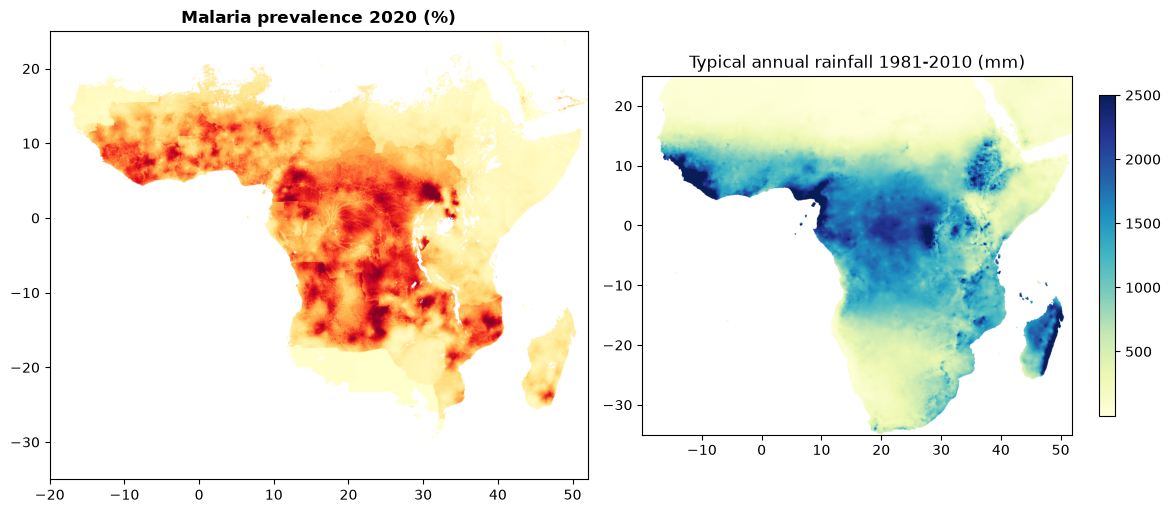

In [14]:
import matplotlib.pyplot as plt
from rasterio.plot import show
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
with rasterio.open(MAP_DIR / "PfPR_2-10_Africa_2020.tif") as src:
    a = src.read(1, masked=True)
    a = np.ma.masked_less(a, 0)
    show(a * 100, transform=src.transform, ax=axes[0], cmap="YlOrRd", vmin=0, vmax=70,
         title="Malaria prevalence 2020 (%)")
im = axes[1].imshow(annual, extent=[lons.min(), lons.max(), lats.min(), lats.max()], cmap="YlGnBu", vmax=2500)
axes[1].set_title("Typical annual rainfall 1981-2010 (mm)")
fig.colorbar(im, ax=axes[1], shrink=0.7)
plt.tight_layout(); plt.show()

## The extracted values

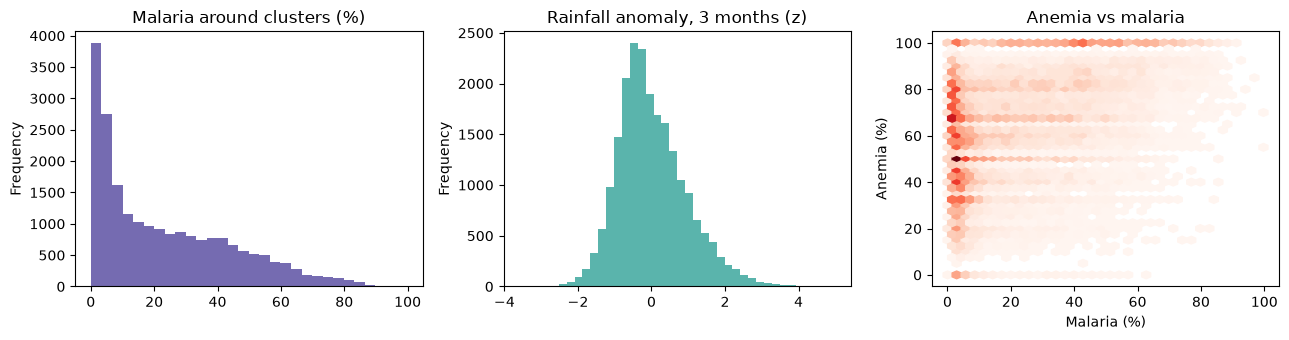

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
cl.pfpr.plot.hist(bins=30, ax=axes[0], color="#756bb1", title="Malaria around clusters (%)")
cl.rain_3mo_z.plot.hist(bins=40, ax=axes[1], color="#5ab4ac", title="Rainfall anomaly, 3 months (z)")
axes[2].hexbin(cl.pfpr, cl.anemia_pct, gridsize=35, cmap="Reds", mincnt=1)
axes[2].set(xlabel="Malaria (%)", ylabel="Anemia (%)", title="Anemia vs malaria")
plt.tight_layout(); plt.show()